# Women in headlines: the analysis, step by step

Companion notebook to the [case study](https://sanjaykoduvalli.github.io/upworthy_headlines/). It walks through the core of the analysis on the **confirmatory** data, the set held back until every method was fixed:

1. Test the test: how often a standard A/B test finds a "winner" when every version is identical (an A/A check)
2. Calibrate: measure the extra noise and correct for it (quasi-binomial)
3. The main model: logistic regression with one intercept per test
4. Check it two ways: a different method (Mantel–Haenszel) and a planted effect

Data: [The Upworthy Research Archive](https://osf.io/jd64p/) (Matias et al., *Scientific Data*, 2021), CC BY 4.0. The full pipeline (loading, cleaning, labeling, tests) is in `pipeline/` and `scripts/build.py`; this notebook reads its outputs.

In [1]:
import os, sys
sys.path.insert(0, "pipeline"); sys.path.insert(0, "pipeline/04_analysis")
os.environ["UPWORTHY_SPLIT"] = "confirmatory"
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from common import load_table          # reads build tables; enforces the confirmatory lock
from felogit import fit, pct_change    # fixed-effects logistic regression (NumPy/SciPy)
pd.set_option("display.precision", 3)

## 1. Test the test

In an **A/A test** every version of the tile was identical, so any difference in clicks is chance. A sound test should call 5% of them significant. The test here is a chi-square test of homogeneity: versions down the side, clicked / didn't click across the top.

In [2]:
packages = load_table("02_clean/packages", split="confirmatory")
aa = packages[packages.is_aa_test.astype(bool) & packages.usable_causal.astype(bool)]

def homogeneity(g):
    clicks, n = g.clicks.to_numpy(float), g.impressions.to_numpy(float)
    rate = clicks.sum() / n.sum()
    exp_c, exp_n = n * rate, n * (1 - rate)
    chi2 = (((clicks - exp_c) ** 2) / exp_c).sum() + ((((n - clicks) - exp_n) ** 2) / exp_n).sum()
    return pd.Series({"arms": len(g), "chi2": chi2, "df": len(g) - 1})

per_test = aa.groupby("clickability_test_id").apply(homogeneity)
per_test["p"] = stats.chi2.sf(per_test.chi2, per_test.df)
print(f"{len(per_test):,} identical-version tests; called significant at 5%: {(per_test.p < 0.05).mean():.1%}")

1,386 identical-version tests; called significant at 5%: 25.9%


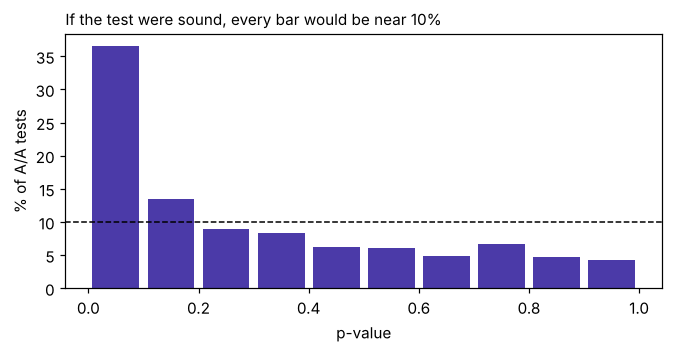

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_test.p, bins=np.linspace(0, 1, 11), weights=np.full(len(per_test), 100 / len(per_test)), color="#4B3AA8", rwidth=0.85)
ax.axhline(10, color="black", lw=1, ls="--")
ax.set_xlabel("p-value"); ax.set_ylabel("% of A/A tests"); ax.set_title("If the test were sound, every bar would be near 10%", loc="left", fontsize=10)
plt.show()

## 2. Calibrate

The test assumes each impression is an independent coin flip. The **dispersion factor** φ measures how much more the click rates of identical tiles vary than coin flips would: the pooled chi-square divided by its degrees of freedom (1 means "exactly like coin flips"). The **quasi-binomial** correction keeps every estimate and divides the chi-square (or multiplies the variance) by φ. To check it fairly, estimate φ on one random half of the A/A tests and count false alarms on the other half.

In [4]:
phi = per_test.chi2.sum() / per_test.df.sum()
rng = np.random.default_rng(20261110)
idx = rng.permutation(len(per_test)); a, b = per_test.iloc[idx[: len(idx) // 2]], per_test.iloc[idx[len(idx) // 2:]]
phi_a, phi_b = a.chi2.sum() / a.df.sum(), b.chi2.sum() / b.df.sum()
held_out = [(stats.chi2.sf(b.chi2 / phi_a, b.df) < 0.05).mean(), (stats.chi2.sf(a.chi2 / phi_b, a.df) < 0.05).mean()]
print(f"phi = {phi:.2f}: identical tiles vary {phi:.1f}x as much as coin flips")
print(f"false alarms after correction, on held-out halves: {held_out[0]:.1%} and {held_out[1]:.1%} (target 5%)")

phi = 1.92: identical tiles vary 1.9x as much as coin flips
false alarms after correction, on held-out halves: 6.8% and 6.3% (target 5%)


## 3. The main model

One row per headline version (identical versions combined), the AI-assigned labels joined on, and a logistic regression of clicks out of impressions with **one intercept per test**, so each headline is compared only with other headlines for the same story. `felogit.fit` profiles the per-test intercepts out instead of building thousands of dummy columns; the result is identical to the dummy-column fit. Significance uses φ estimated from the model itself (the more cautious choice: real headlines also differ in ways the labels don't capture).

In [5]:
v = load_table("04_analysis/confirmatory/m1_input")
terms = ["female", "male", "both", "positive", "negative"]
m = fit(v[terms].values, v.clicks, v.impressions, v.clickability_test_id, terms)
phi_model = m["phi_pearson"]
se = m["se_raw"] * np.sqrt(phi_model)
result = pd.DataFrame({
    "change in click rate": [f"{x:+.1f}%" for x in pct_change(m["beta"])],
    "95% interval": [f"{pct_change(b - 1.96 * s):+.1f}% to {pct_change(b + 1.96 * s):+.1f}%" for b, s in zip(m["beta"], se)],
    "p": 2 * stats.norm.sf(np.abs(m["beta"] / se)),
}, index=["a woman (vs. no gendered person)", "a man (vs. none)", "both", "positive tone (vs. neutral)", "negative tone (vs. neutral)"])
print(f"{m['n_groups']:,} tests, {m['n_rows']:,} headline versions, model phi = {phi_model:.2f}")
result

9,813 tests, 45,957 headline versions, model phi = 3.92


,change in click rate,95% interval,p
a woman (vs. no gendered person),+8.9%,+7.2% to +10.6%,2.234e-27
a man (vs. none),+7.4%,+6.0% to +8.8%,1.926e-26
both,+21.5%,+19.0% to +24.1%,6.734e-74
positive tone (vs. neutral),-1.6%,-2.6% to -0.5%,5.265e-03
negative tone (vs. neutral),+3.1%,+1.9% to +4.3%,6.070e-07


In [6]:
# The question that matters: a woman vs. a man (difference of two coefficients)
i, j = terms.index("female"), terms.index("male")
d = m["beta"][i] - m["beta"][j]
se_d = np.sqrt((m["cov_raw"][i, i] + m["cov_raw"][j, j] - 2 * m["cov_raw"][i, j]) * phi_model)
print(f"woman vs. man: {pct_change(d):+.1f}% (95% interval {pct_change(d - 1.96 * se_d):+.1f}% to {pct_change(d + 1.96 * se_d):+.1f}%), "
      f"p = {2 * stats.norm.sf(abs(d / se_d)):.2f}")

woman vs. man: +1.4% (95% interval -0.5% to +3.3%), p = 0.16


## 4. Check it two ways

**A different method.** The Mantel–Haenszel odds ratio pools a 2×2 table (woman-centered vs. no gendered person × clicked vs. not) within each test. It doesn't adjust for tone, so it should be close to the model, not identical.

**A planted effect.** Rebuild the clicks as coin flips at each version's own click rate, once as-is and once with woman-centered versions 10% more clickable. The model should find about +10%.

In [7]:
num = den = 0.0
for _, g in v[v.gender.isin(["female", "none"])].groupby("clickability_test_id"):
    f, o = g[g.gender == "female"], g[g.gender == "none"]
    if len(f) and len(o):
        a_, b_ = f.clicks.sum(), f.impressions.sum() - f.clicks.sum()
        c_, d_ = o.clicks.sum(), o.impressions.sum() - o.clicks.sum()
        n_ = a_ + b_ + c_ + d_; num += a_ * d_ / n_; den += b_ * c_ / n_
print(f"Mantel-Haenszel, woman vs. none: {100 * (num / den - 1):+.1f}%   (model: {pct_change(m['beta'][0]):+.1f}%)")

X, n = v[terms].to_numpy(float), v.impressions.to_numpy()
rate = v.clicks.to_numpy() / n
shifts = []
for _ in range(5):
    base = fit(X, rng.binomial(n, rate), n, v.clickability_test_id, terms)["beta"][0]
    plant = fit(X, rng.binomial(n, np.where(X[:, 0] == 1, rate * 1.10, rate)), n, v.clickability_test_id, terms)["beta"][0]
    shifts.append(100 * (np.exp(plant - base) - 1))
print(f"planted +10%, recovered: {np.mean(shifts):+.1f}% on average over {len(shifts)} runs")

Mantel-Haenszel, woman vs. none: +9.4%   (model: +8.9%)
planted +10%, recovered: +10.2% on average over 5 runs


## Where to go next

- Topic framing, the gender × topic interactions and the sensitivity checks: `pipeline/04_analysis/main_effects.py`, `topic_effects.py`, results in `docs/results/`
- Every check the build runs: `scripts/build.py`, `scripts/checks/`, `tests/`
- Every decision, and who made it: `docs/decision_register.md`; where each number comes from: `docs/results/provenance.md`